# KKBOX: isolated training-only exploratory analysis

**Question:** which cutoff-available recorded signals are associated with supplied February 2017 churn outcomes?
This is a single-cohort retrospective benchmark, not a historical campaign simulation.
The cutoff is January 31, 2017. No models or final evaluation metrics are produced.

The preparation CLI freezes user-disjoint SHA-256 partitions before extracting training labels.
This notebook has one fixed private training input and no raw-label path or partition selector.
Filesystem permissions are not a security sandbox: isolation is enforced by the pipeline contract and tested data flow.
See [methodology](../docs/methodology.md) for reproduction, field limitations and the candidate rule.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from retention_lab.eda import load_training, summarize, plot_rates, CHARTS

training = load_training(ROOT / "data/processed/kkbox-eda-v1")
summary = summarize(training)
print(json.dumps({key: summary[key] for key in
                 ["scope", "training_users", "churners", "prevalence"]}, indent=2))

{
  "scope": "training only",
  "training_users": 523998,
  "churners": 29015,
  "prevalence": 0.055372348749422706
}


## Data quality and marginal distributions

One row per training subscriber, derived from exact full-field distinct pre-cutoff records.
Duplicate counts refer to repeated complete rows, never duplicate subscriber/day keys.
Additional latest fields use independent agreement on the selected latest day: conflicts are unknown,
not a choice based on file order. Missingness below includes these unknown values.

`observed_history_days` is time since the first **available** transaction through the cutoff, not true tenure.
Transaction counts include all distinct recorded events and must not be called successful payments.
Expiry before the event and expiry beyond February 1, 2018 are descriptive exception flags, not automatic data corrections.
The latter threshold is a transparent diagnostic, not a verified business invalidity rule.

In [2]:
print(json.dumps({key: summary[key] for key in
                 ["missing_fields", "quality_totals", "distributions", "payment_method_counts"]},
                 indent=2, sort_keys=True))

{
  "distributions": {
    "distinct_transactions": {
      "25%": 8.0,
      "50%": 15.0,
      "75%": 23.0,
      "count": 523998.0,
      "max": 63.0,
      "mean": 14.871936534108908,
      "min": 1.0,
      "std": 8.340879968490945
    },
    "january_transactions": {
      "25%": 1.0,
      "50%": 1.0,
      "75%": 1.0,
      "count": 523998.0,
      "max": 6.0,
      "mean": 0.9795438150527292,
      "min": 0.0,
      "std": 0.19088903829620707
    },
    "latest_amount": {
      "25%": 99.0,
      "50%": 149.0,
      "75%": 149.0,
      "count": 523998.0,
      "max": 2000.0,
      "mean": 149.777854113947,
      "min": 0.0,
      "std": 169.04718088969315
    },
    "latest_list_price": {
      "25%": 99.0,
      "50%": 149.0,
      "75%": 149.0,
      "count": 523998.0,
      "max": 2000.0,
      "mean": 150.14447765067806,
      "min": 0.0,
      "std": 168.89137612535114
    },
    "latest_plan_days": {
      "25%": 30.0,
      "50%": 30.0,
      "75%": 30.0,
      "count":

## How to read the five charts

Each bar is supplied churners / subscribers **within that group**, with denominators on the axis
and the complete aggregate table below. Every training user appears once in every chart;
unknown values are explicitly retained. Numeric bins use training marginal quartiles only,
with duplicate boundaries collapsed; no labels are used to choose boundaries.
A single distinct known numeric value becomes one group. These are descriptive associations,
not effects of changing renewal, duration, price or subscriber history. No confidence or causal claim is made.

## Is recorded auto-renew off associated with higher supplied churn?

The Off/On rates address hypothesis 1. Configuration may reflect plan selection, channel and other confounding; this does not measure an intervention.

**Observed:** 19,294/63,335 off users churned (30.46%), versus 9,721/460,663 on users (2.11%). This supports the descriptive direction of hypothesis 1, not a causal effect or out-of-sample result.

[
  {
    "group": "Off",
    "users": 63335,
    "churners": 19294,
    "churn_rate": 0.3046340885766164
  },
  {
    "group": "On",
    "users": 460663,
    "churners": 9721,
    "churn_rate": 0.02110219401167448
  }
]


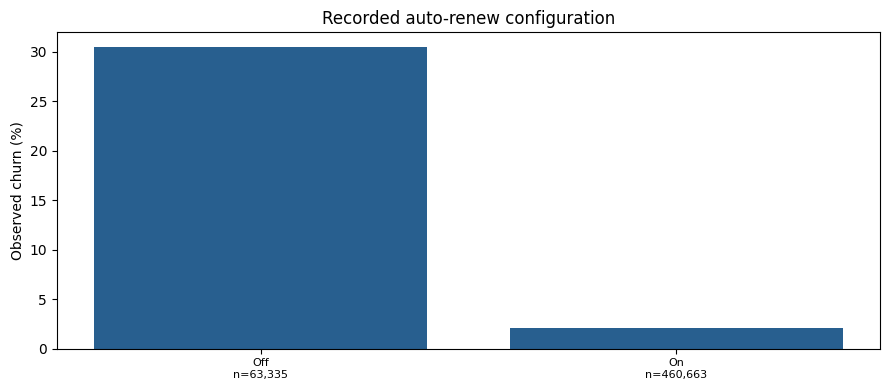

In [3]:
table = summary["charts"]["auto_renew"]
print(json.dumps(table, indent=2))
fig = plot_rates(table, CHARTS["auto_renew"])
plt.show()
plt.close(fig)

## Is shorter observed history associated with higher churn?

Compare the shortest and longest numeric intervals for hypothesis 2, without treating missing earlier records as a new subscriber or assuming a monotone pattern.

**Observed:** churn declines across the four marginal-history groups: 7.30%, 6.63%, 4.90%, 3.30% (denominators 131,260; 131,132; 131,604; 130,002). The direction agrees with hypothesis 2, but longer observed coverage is not proof of actual tenure.

[
  {
    "group": "(-0.001, 260.0]",
    "users": 131260,
    "churners": 9583,
    "churn_rate": 0.0730077708365077
  },
  {
    "group": "(260.0, 478.0]",
    "users": 131132,
    "churners": 8691,
    "churn_rate": 0.06627672879236189
  },
  {
    "group": "(478.0, 734.0]",
    "users": 131604,
    "churners": 6454,
    "churn_rate": 0.04904106258168445
  },
  {
    "group": "(734.0, 761.0]",
    "users": 130002,
    "churners": 4287,
    "churn_rate": 0.03297641574745004
  }
]


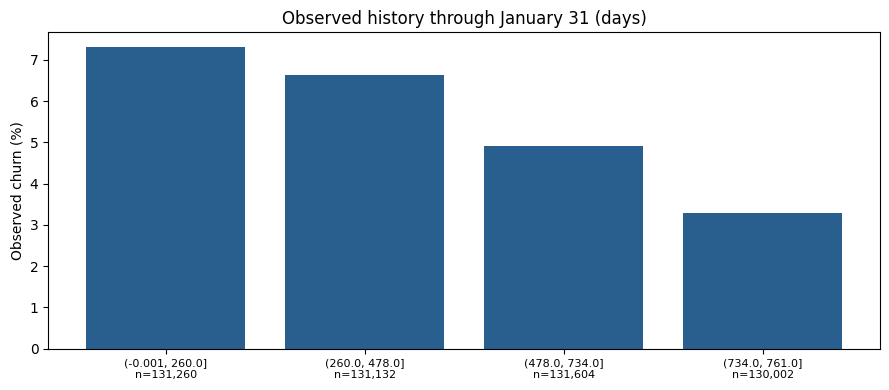

In [4]:
table = summary["charts"]["observed_history_days"]
print(json.dumps(table, indent=2))
fig = plot_rates(table, CHARTS["observed_history_days"])
plt.show()
plt.close(fig)

## Does churn differ by distinct January transaction count?

Recorded events include possible renewals, cancellations and plan changes. A larger count is not necessarily more engagement or more successful payments.

**Observed:** 28,739/520,925 users with zero or one distinct January record churned (5.52%), versus 276/3,073 users with more than one (8.98%). Tied quartiles collapse into only two uneven groups; zero and one are not distinguished by these marginal bins.

[
  {
    "group": "(-0.001, 1.0]",
    "users": 520925,
    "churners": 28739,
    "churn_rate": 0.05516917022604022
  },
  {
    "group": "(1.0, 6.0]",
    "users": 3073,
    "churners": 276,
    "churn_rate": 0.08981451350471852
  }
]


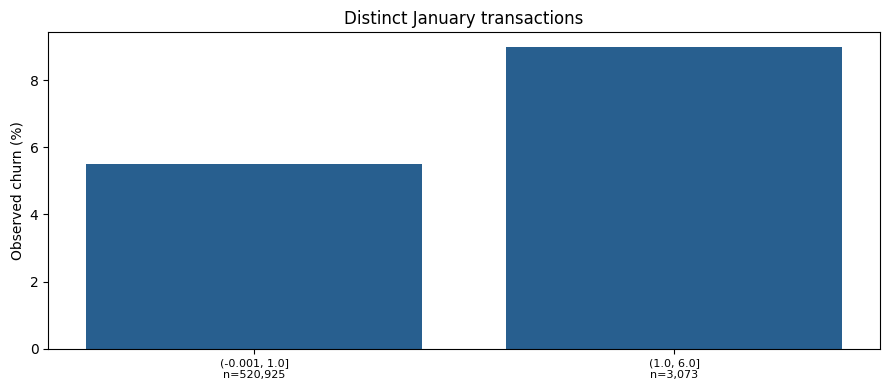

In [5]:
table = summary["charts"]["january_transactions"]
print(json.dumps(table, indent=2))
fig = plot_rates(table, CHARTS["january_transactions"])
plt.show()
plt.close(fig)

## Does churn differ by latest agreed recorded plan duration?

Agreement is checked independently on the latest observed day. Unknown includes same-day conflicts or absent values; recorded duration need not equal remaining membership or realized use.

**Observed:** 22,707/510,754 users with recorded duration up to 30 days churned (4.45%), versus 6,308/13,244 above 30 (47.63%). This broad comparison does not isolate duration from renewal configuration or plan/channel mix.

[
  {
    "group": "(0.999, 30.0]",
    "users": 510754,
    "churners": 22707,
    "churn_rate": 0.044457801603120094
  },
  {
    "group": "(30.0, 450.0]",
    "users": 13244,
    "churners": 6308,
    "churn_rate": 0.47629115070975536
  }
]


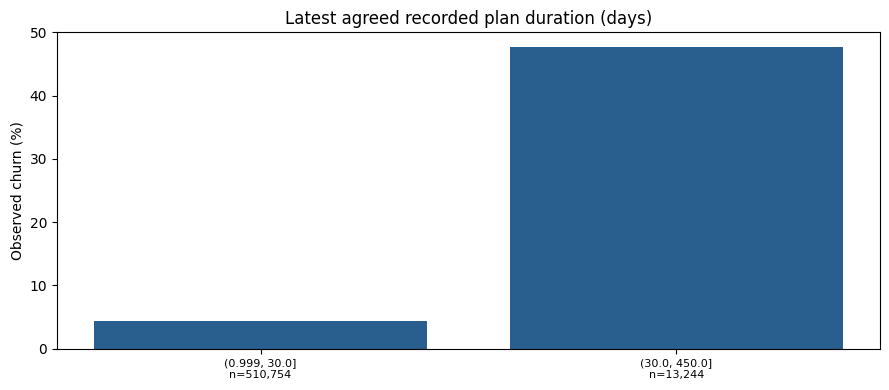

In [6]:
table = summary["charts"]["latest_plan_days"]
print(json.dumps(table, indent=2))
fig = plot_rates(table, CHARTS["latest_plan_days"])
plt.show()
plt.close(fig)

## Does churn differ by latest agreed recorded amount?

Agreement is checked independently on the latest observed day. This amount is not verified revenue, realized value or a causal price sensitivity measure.

**Observed:** rates are 2.09% for recorded amount up to 99 (n=231,723), 5.13% above 99 through 149 (n=231,813), and 20.29% above 149 (n=60,462). Amount units/business realization are not independently certified; this is not a price elasticity estimate.

[
  {
    "group": "(-0.001, 99.0]",
    "users": 231723,
    "churners": 4848,
    "churn_rate": 0.02092153131109126
  },
  {
    "group": "(99.0, 149.0]",
    "users": 231813,
    "churners": 11897,
    "churn_rate": 0.05132153934421279
  },
  {
    "group": "(149.0, 2000.0]",
    "users": 60462,
    "churners": 12270,
    "churn_rate": 0.2029373821573881
  }
]


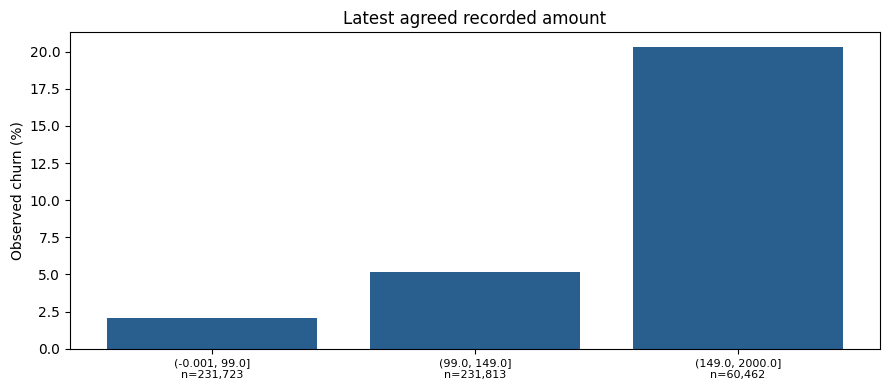

In [7]:
table = summary["charts"]["latest_amount"]
print(json.dumps(table, indent=2))
fig = plot_rates(table, CHARTS["latest_amount"])
plt.show()
plt.close(fig)

## Hypothesis 3: an observed on-to-off transition

Compare users with at least one observed `1 → 0` transition against users whose **every observed day**
has an unambiguous on state. Consecutive observed days need not be consecutive calendar days.
An ambiguous day breaks the transition chain, rather than being skipped or silently resolved.
Other / unknown histories remain visible as a separate group, not part of the comparator.
A user can switch back on later; this hypothesis concerns an observed transition, not necessarily the final state.
The comparison is exploratory and confounded; it is not a claim that switching renewal off causes churn.

**Observed:** 1,879/13,586 transition users churned (13.83%), versus 8,660/428,138 always-on users (2.02%). Other histories account for 82,274 users. This agrees with hypothesis 3 descriptively, without treating the groups as exchangeable.

In [8]:
print(json.dumps(summary["hypothesis_transition"], indent=2))

[
  {
    "group": "Always on",
    "users": 428138,
    "churners": 8660,
    "churn_rate": 0.02022712303042477
  },
  {
    "group": "Observed on-to-off",
    "users": 13586,
    "churners": 1879,
    "churn_rate": 0.13830413661121743
  },
  {
    "group": "Other / unknown",
    "users": 82274,
    "churners": 18476,
    "churn_rate": 0.22456669178598343
  }
]


## Candidate rule and limits

**Documented only:** prioritize recorded auto-renew off; tie-break by ascending SHA-256 digest
from the approved split, then subscriber identifier. Do not implement, tune or score this baseline here.

The five tables and transition comparison assess three exploratory hypotheses:
1. Auto-renew off is associated with higher churn.
2. Shorter observed history is associated with higher churn.
3. An observed on-to-off change is associated with higher churn than remaining on on every observed day.

No validation/final outcome prevalence is read or reported. No temporal transfer validation exists.
Prior Phase 1 work inspected global labels; this phase cannot undo historical exposure, but its new artifacts,
comparisons and notebook are training-only. Arrival timestamps, event adjudication and the official labeler
are unverified; supplied outcomes are accepted under the restricted protocol. No saved customers,
retained revenue or causal benefit is estimated. The next phase requires separate authorization.